# Competitor Mapping Tool: strategic groups as a clustering problem

Industry: **bookkeeping, tax and advisory services for small businesses** (US). The tool takes a list of competitors, reads each firm's own
public pages, records at least seven attributes per firm **with the source URL and retrieval date of every value**, and then lets the data
choose the map axes (**PCA**) and the groups (**k-means**, checked with hierarchical clustering and stability runs). A hypothetical point for
Fine Line Financials is projected onto the finished map **after** fitting, so it cannot move the groups.

**Evidence rule.** A value is used only if it was read from a cached public page; where it rests on wording, a short verbatim quote is
re-checked here against that page. A value that cannot be read or whose quote is not found is **missing**, and the missing-value rule
below says what happens to it. No number is guessed.

**Fetch rule.** Plain `python-requests` user agent, never changed; `robots.txt` is read first; a page that answers 403, times out or is
parked is recorded as "not available" and is not retried with another client. Emails and phone numbers are redacted from the cache.
Everything read is cached in `competitor-map/cache/`, so a fresh clone runs offline (it uses the kept text lines in `cache/pages/`).

| Step | Done by |
|---|---|
| Choosing the firms, reading their pages and writing `attributes.json` (values, URLs, quotes); choosing the checklist, encodings and rules | Claude Code (LLM agent) during the build session, as stated judgment |
| Fetching and caching every page, re-checking every quote, counting services, encoding, imputing, PCA, k-means, hierarchical clustering, stability runs, projection, charts | Plain, deterministic Python in this notebook |

In [1]:
# ---------------------------------------------------------------- inputs (change these)
COMPETITORS_FILE = "competitors.json"   # firm list: name, pages to read, and the group I would draw by hand (used only for comparison)
ATTRIBUTES_FILE = "attributes.json"     # hand-read values with URL + quote for each firm
NPS_FILE = "../nps-scorer/nps_data.json"   # earlier deliverable: Google Maps review counts reused for the quality signal

SEED = 7
K_RANGE = range(2, 9)                   # candidate numbers of groups
MIN_GROUP = 2                           # a "group" of one firm describes a firm, not a strategic group
MAX_MISSING_SHARE = 0.50                # a feature missing for more than half the fitted firms is dropped from the fit
MAX_MISSING_PER_FIRM = 2                # a firm missing more than 2 of the attributes kept in the fit is shown but not fitted

# Hypothetical point: Fine Line Financials. ASSUMPTIONS, not data. Projected after fitting; never used to fit.
MY_FIRM = {
    "name": "Fine Line Financials (hypothetical)",
    "price_scenarios": [125, 200, 350],                      # monthly bookkeeping, USD; pricing is not final
    "price_published": 1,                                    # assumes the chosen price would be shown publicly
    "services": ["free price check", "business setup package", "tax-time organization",
                 "one-time bookkeeping cleanup", "monthly bookkeeping"],
    "locations": 0, "channel": "online", "niche": 1, "files_tax": 0,
}

In [2]:
import json, re, sys, math, warnings, datetime as dt
warnings.filterwarnings("ignore", message="urllib3 v2 only supports OpenSSL")   # macOS LibreSSL notice; it would print a local path
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from adjustText import adjust_text
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.optimize import linear_sum_assignment
from IPython.display import display, HTML, Image as IPImage
import mistune

HERE = Path.cwd() if (Path.cwd() / "competitors.json").exists() else Path.cwd() / "competitor-map"
sys.path.insert(0, str(HERE))
import fetch                                                # cached, robots-aware fetcher (competitor-map/fetch.py)
_md = mistune.create_markdown(plugins=["table"])
show = lambda md: display(HTML(_md(md)))
pd.set_option("display.max_colwidth", 90)

COMP = json.loads((HERE / COMPETITORS_FILE).read_text())["competitors"]
ATTR = json.loads((HERE / ATTRIBUTES_FILE).read_text())["firms"]
NPS = json.loads((HERE / NPS_FILE).read_text())
NAME = {c["slug"]: c["name"] for c in COMP}
print(f"{len(COMP)} firms in the input list; user agent for every request: {fetch.UA}")

26 firms in the input list; user agent for every request: python-requests/2.32.5


## 1. Read every page (cached) and check that each firm is still operating

A firm is **operating** if its homepage loads (HTTP 200, not a parked or for-sale page) and the page text shows the current or previous year
(a 2025 or 2026 date, copyright line or price table). A firm whose site cannot be read is kept in the table as **not readable** and is not
fitted; a firm whose domain is parked is **dropped as defunct**.

In [3]:
PAGES = {}
rows = []
for c in COMP:
    for u in c["pages"]:
        m = fetch.fetch(u)
        PAGES[u] = m
        rows.append({"firm": c["name"], "url": u, "status": m["status"], "robots": m["robots"], "retrieved": m["retrieved"],
                     "text from": m.get("from"), "note": m.get("note", "")})
PAGE_TABLE = pd.DataFrame(rows)
display(PAGE_TABLE)
print(f"{len(PAGE_TABLE)} pages; {int((PAGE_TABLE.status == 200).sum())} read; {int((PAGE_TABLE.status != 200).sum())} not available; "
      f"robots.txt disallowed {int((PAGE_TABLE.robots == 'DISALLOWED').sum())}")

def norm(s):
    return re.sub(r"\s+", " ", (s or "").replace("’", "'").replace("‘", "'")).strip().lower()

STATUS = {}
for c in COMP:
    home = PAGES[c["pages"][0]]
    readable = [u for u in c["pages"] if PAGES[u]["text"] and not PAGES[u].get("parked")]
    if home.get("parked"):
        STATUS[c["slug"]] = ("dropped: defunct", f"homepage is a parked / for-sale page ({home.get('final_url', home['url'])})")
    elif not readable:
        STATUS[c["slug"]] = ("not readable", f"every page answered {home['status']} to a plain request; not retried with another client")
    else:
        current = re.search(r"20(25|26)", " ".join(PAGES[u]["text"] for u in readable))
        STATUS[c["slug"]] = ("operating" if current else "operating (no current date seen)",
                             f"{len(readable)} of {len(c['pages'])} pages read; a 2025/2026 date appears in the text" if current else
                             f"{len(readable)} of {len(c['pages'])} pages read")
ST = pd.DataFrame([{"firm": NAME[s], "status": v[0], "basis": v[1], "from nps-scorer": bool(next(c for c in COMP if c['slug'] == s).get("start"))}
                   for s, v in STATUS.items()])
display(ST)

,firm,url,status,robots,retrieved,text from,note
0,Kopsa Otte CPAs & Advisors,https://www.kopsaotte.com/,200,allowed,2026-11-10,full text,
1,Kopsa Otte CPAs & Advisors,https://www.kopsaotte.com/about-kopsa-otte/services/,403,allowed,2026-11-10,none,HTTP 403: not available (not retried with another client)
2,Kopsa Otte CPAs & Advisors,https://www.kopsaotte.com/salons-spas/,403,allowed,2026-11-10,none,HTTP 403: not available (not retried with another client)
3,Kopsa Otte CPAs & Advisors,https://www.kopsaotte.com/about-kopsa-otte/,403,allowed,2026-11-10,none,HTTP 403: not available (not retried with another client)
4,Xendoo,https://www.xendoo.com/,403,allowed,2026-11-10,none,HTTP 403: not available (not retried with another client)
...,...,...,...,...,...,...,...
94,Monaco CPA,https://www.monacocpa.cpa/services,200,allowed,2026-11-10,full text,
95,Monaco CPA,https://www.monacocpa.cpa/industries/salons-spas,200,allowed,2026-11-10,full text,
96,Monaco CPA,https://www.monacocpa.cpa/locations/new-jersey-cpa,200,allowed,2026-11-10,full text,
97,Padgett Business Services,https://www.smallbizpros.com/,403,robots.txt not readable,2026-11-10,none,HTTP 403: not available (not retried with another client)


99 pages; 83 read; 16 not available; robots.txt disallowed 0


,firm,status,basis,from nps-scorer
0,Kopsa Otte CPAs & Advisors,operating (no current date seen),1 of 4 pages read,True
1,Xendoo,not readable,every page answered 403 to a plain request; not retried with another client,True
2,Elite Business Solutions,dropped: defunct,homepage is a parked / for-sale page (https://expireddomains.com/domain/elitebsolution...,True
3,Jasmine Thomas & Associates,dropped: defunct,homepage is a parked / for-sale page (https://jasminethomasassociates.com/),True
4,Bench,operating,5 of 5 pages read; a 2025/2026 date appears in the text,False
5,Pilot,operating,5 of 5 pages read; a 2025/2026 date appears in the text,False
6,Bookkeeper360,operating,4 of 4 pages read; a 2025/2026 date appears in the text,False
7,1-800Accountant,operating,6 of 6 pages read; a 2025/2026 date appears in the text,False
8,inDinero,operating,3 of 5 pages read; a 2025/2026 date appears in the text,False
9,Ignite Spot,operating,4 of 5 pages read; a 2025/2026 date appears in the text,False


**Firms carried over from `nps-scorer/nps_data.json`.** That deliverable scored four firms. Two are now gone: Elite Business Solutions'
domain redirects to a domain-for-sale page and Jasmine Thomas & Associates' domain is a parked page, so both are **dropped as defunct**
(the NPS notes had already flagged both). Xendoo's site answers HTTP 403 to every plain request, so only its review count from the NPS run
can be used. Its Google listing was active in October 2026, but its pricing, services and niche could not be read here, so it is shown
and **not fitted**. The same applies to Block Advisors (H&R Block), Padgett Business Services and Straight Talk CPAs. A Provo salon-finance
firm that came up in a search could not be found at any working domain, so it was left out.

## 2. Attribute 2: service breadth, counted by code

The checklist is defined here. A service counts when its pattern appears in a **listing line** (12 words or fewer: a menu item, heading or
plan bullet) on the firm's homepage, pricing or services pages. Longer prose, FAQ answers and negated lines ("not included", "we could sell
you tax prep...") are skipped, and about pages are excluded so staff bios cannot add services. The first matching line is printed for each
hit so every count can be checked. If a page whose address names "services" could not be read, breadth is **missing** (it would be
undercounted) and is imputed under the rule in section 5. Limitation: this is keyword evidence, so it can still count a service the firm only names.

In [4]:
CHECKLIST = {
    "Monthly bookkeeping": r"bookkeep",
    "Catch-up / cleanup": r"catch[- ]?up|clean[- ]?up",
    "Payroll": r"\bpayroll\b",
    "Business tax return prep / filing": r"(business|corporate) (income )?tax (prep|return|filing)|business returns?\b|business taxes|\b1120|\b1065\b|schedule c\b",
    "Individual tax returns": r"individual (income )?(tax|return)|personal (income )?tax|\b1040\b",
    "Tax planning / advisory": r"tax (planning|advisory|strategy|strategies)",
    "CFO / FP&A advisory": r"\bcfo\b|controller services|forecast|budgeting",
    "Sales-tax filing": r"sales[- ]tax",
    "Entity formation / business setup": r"entity formation|business formation|new entity|business setup|form (an|your) (llc|entity|business)|incorporation services",
    "Loan-readiness / financing support": r"loan[- ]read|lender[- ]read|bank[- ]read|sba loan|loan application|financing support",
    "Bill pay / AP-AR / invoicing": r"bill pay|accounts payable|accounts receivable|\bap/ar\b|invoic",
    "1099 / information returns": r"\b1099",
    "IRS notices / audit support": r"audit (defense|protection|representation|support)|irs (notice|letter|representation|correspondence)|tax resolution|tax debt",
    "HR / benefits": r"(?-i:\bHR\b)|human resources|benefits administration",
    "R&D tax credits": r"r&d tax|research (and|&) development",
}
CHECK_RX = {k: re.compile(v, re.I) for k, v in CHECKLIST.items()}
NEGATION = re.compile(r"not included|not include|n't include|does not include|could sell you|we (do not|don't) (offer|provide|file)", re.I)
MAX_WORDS = 12
BEAUTY_RX = re.compile(r"salon|\bspas?\b|esthetic|stylist|nail tech|nail salon|\blash(es)?\b|\bbrows?\b|barber|beauty|cosmetolog|makeup artist", re.I)

def service_pages(c):
    return [u for u in c["pages"] if PAGES[u]["text"] and not PAGES[u].get("parked") and "about" not in u.lower()]

BREADTH, BREADTH_EVIDENCE, BEAUTY_HITS = {}, {}, {}
for c in COMP:
    hits = {}
    for u in service_pages(c):
        for line in PAGES[u]["text"].split("\n"):
            if BEAUTY_RX.search(line):
                BEAUTY_HITS.setdefault(c["slug"], []).append((u, line[:110]))
            if len(line.split()) > MAX_WORDS or NEGATION.search(line):
                continue
            for k, rx in CHECK_RX.items():
                if k not in hits and rx.search(line):
                    hits[k] = (u, line[:110])
    services_unread = any("service" in u.lower() and not PAGES[u]["text"] for u in c["pages"])
    BREADTH[c["slug"]] = len(hits) if service_pages(c) and not services_unread else None
    BREADTH_EVIDENCE[c["slug"]] = hits

bt = pd.DataFrame([{"firm": NAME[s], **{k: ("x" if k in BREADTH_EVIDENCE[s] else "") for k in CHECKLIST}, "breadth": BREADTH[s]}
                   for s in BREADTH if service_pages(next(c for c in COMP if c["slug"] == s))]).set_index("firm")
display(bt)
MY_BREADTH = sum(any(rx.search(s) for s in MY_FIRM["services"]) for rx in CHECK_RX.values())
print(f"Fine Line Financials' listed services hit {MY_BREADTH} checklist items (same patterns): "
      + ", ".join(k for k, rx in CHECK_RX.items() if any(rx.search(s) for s in MY_FIRM["services"])))

,Monthly bookkeeping,Catch-up / cleanup,Payroll,Business tax return prep / filing,Individual tax returns,Tax planning / advisory,CFO / FP&A advisory,Sales-tax filing,Entity formation / business setup,Loan-readiness / financing support,Bill pay / AP-AR / invoicing,1099 / information returns,IRS notices / audit support,HR / benefits,R&D tax credits,breadth
firm,,,,,,,,,,,,,,,,
Kopsa Otte CPAs & Advisors,,,,,,,,,,,,,,,,NaN
Bench,x,x,x,x,,x,,,,,,,,,,5.0
Pilot,x,,x,x,x,,x,,,,x,x,,,x,8.0
Bookkeeper360,x,x,x,x,x,x,x,x,,,x,,,x,x,11.0
1-800Accountant,x,x,x,x,x,x,,,x,,x,x,x,,,10.0
inDinero,x,x,x,x,,,x,,,,,,,,,NaN
Ignite Spot,x,x,x,x,x,x,x,x,,,x,,,,,9.0
Merritt Bookkeeping,x,,,,,,x,,,,,,,,,2.0
QuickBooks Live (Intuit),x,x,x,x,,,x,x,,,x,x,x,,,9.0


Fine Line Financials' listed services hit 3 checklist items (same patterns): Monthly bookkeeping, Catch-up / cleanup, Entity formation / business setup


Evidence for each hit (firm, checklist item, the line that matched):

In [5]:
ev = pd.DataFrame([{"firm": NAME[s], "item": k, "matched line": v[1], "url": v[0]} for s, h in BREADTH_EVIDENCE.items() for k, v in h.items()])
display(ev)

,firm,item,matched line,url
0,Bench,Monthly bookkeeping,Online Bookkeeping Done for You | Bench,https://www.bench.co/
1,Bench,Catch-up / cleanup,Catch-up bookkeeping,https://www.bench.co/
2,Bench,Tax planning / advisory,Up to four tax advisory calls annually,https://www.bench.co/
3,Bench,Business tax return prep / filing,End-to-end business tax filing,https://www.bench.co/
4,Bench,Payroll,Payroll,https://www.bench.co/industry/local-business
...,...,...,...,...
124,Monaco CPA,IRS notices / audit support,An IRS notice about crypto,https://www.monacocpa.cpa/
125,Monaco CPA,Sales-tax filing,NJ Sales Tax,https://www.monacocpa.cpa/
126,Monaco CPA,Payroll,Payroll Compliance Support,https://www.monacocpa.cpa/
127,Monaco CPA,Individual tax returns,Individual Tax Preparation,https://www.monacocpa.cpa/


## 3. Attributes 1 and 3-7: hand-read values, every quote re-checked against the cached page

* **1 Starting monthly price**: lowest published monthly price for a recurring plan. Status is one of `published`, `quote_only`
  (custom quote), `no_monthly_plan` (priced per return or per call) or `not_available` (page unreadable or price not in the HTML).
* **3 Geographic footprint**: number of client walk-in locations the firm states (online firms with no listed office = 0). Nearly every
  firm says it serves the whole US, so "states served" would not separate anyone; physical locations do.
* **4 Channel mix**: `online` (0) = no walk-in office; `hybrid` (1) = mainly remote with some physical presence; `office` (2) = a branch
  network is the main channel. Ordinal because each step adds physical presence. "Inferred" means no office is mentioned anywhere on the pages read.
* **5 Quality signal**: review score and count, from `nps-scorer` (Google Maps) where available, otherwise as the firm displays a
  third-party rating on its own site (self-selected, flagged).
* **6 Niche focus**: yes if the firm has a page or section addressed to salons, spas or beauty businesses; a passing mention in a list of
  many industries is a no (the code's keyword scan is printed so the call can be checked).
* **7 Files tax returns**: yes if the firm's own pages say it prepares or files tax returns (including as a paid add-on).

In [6]:
CHECKS = []
def checked(slug, attr, v):
    """Return v's value if its quote (when present) is found on its cached page; otherwise None (missing)."""
    q, u = v.get("quote"), v.get("url", "")
    if not u.startswith("http"):
        return True
    page = PAGES.get(u) or fetch.fetch(u)
    found = (not q) or (page["text"] is not None and norm(q) in norm(page["text"].replace("\n", " ")))
    CHECKS.append({"firm": NAME[slug], "attribute": attr, "quote": q or "(no quote: value rests on absence / page read)",
                   "url": u, "retrieved": page["retrieved"], "found": found})
    return found

for s, f in ATTR.items():
    for a, v in f.items():
        v["_ok"] = checked(s, a, v)
CHK = pd.DataFrame(CHECKS)
display(CHK)
n_q = int((CHK.quote.str[0] != "(").sum())
print(f"{n_q} quotes checked, {int(CHK[CHK.quote.str[0] != '('].found.sum())} found on their cached page; {int((~CHK.found).sum())} not found")
assert CHK.found.all(), "a quote was not found: its value must be treated as missing (fix attributes.json or let the rule drop it)"

,firm,attribute,quote,url,retrieved,found
0,Kopsa Otte CPAs & Advisors,price,(no quote: value rests on absence / page read),https://www.kopsaotte.com/,2026-11-10,True
1,Kopsa Otte CPAs & Advisors,files_tax,"In addition to tax planning and preparation, clients rely on Kopsa Otte",https://www.kopsaotte.com/,2026-11-10,True
2,Kopsa Otte CPAs & Advisors,niche,"working with salons, spas & distributors",https://www.kopsaotte.com/,2026-11-10,True
3,Kopsa Otte CPAs & Advisors,channel,work with beauty-based businesses in 45 states,https://www.kopsaotte.com/,2026-11-10,True
4,Kopsa Otte CPAs & Advisors,footprint,"306 East Seventh Street York, NE 68467",https://www.kopsaotte.com/,2026-11-10,True
...,...,...,...,...,...,...
105,Monaco CPA,price,Monthly Bookkeeping Starting at $300/mo,https://www.monacocpa.cpa/pricing,2026-11-10,True
106,Monaco CPA,files_tax,"Personal tax returns for W-2, freelance, and self-employed filers.",https://www.monacocpa.cpa/pricing,2026-11-10,True
107,Monaco CPA,niche,Accounting & Tax for Salons and Spas,https://www.monacocpa.cpa/industries/salons-spas,2026-11-10,True
108,Monaco CPA,channel,"Based in Livingston, NJ (virtual practice; no walk-in office).",https://www.monacocpa.cpa/locations/new-jersey-cpa,2026-11-10,True


82 quotes checked, 82 found on their cached page; 0 not found


### Quality signal: reuse the NPS data

In [7]:
nps = {c["slug"]: c for c in NPS["companies"]}
for slug in ("kopsa_otte", "xendoo"):
    h = nps[slug]["histogram"]
    n = sum(h.values())
    ATTR[slug]["reviews"]["count"] = n
    ATTR[slug]["reviews"]["score"] = round(sum(int(k) * v for k, v in h.items()) / n, 2)
    ATTR[slug]["reviews"]["retrieved"] = nps[slug]["retrieved"]
    print(f"{NAME[slug]}: {n} Google Maps reviews, mean {ATTR[slug]['reviews']['score']} stars (nps-scorer, read {nps[slug]['retrieved']})")
print("Not reused: Elite Business Solutions and Jasmine Thomas & Associates (defunct, see section 1).")

Kopsa Otte CPAs & Advisors: 2 Google Maps reviews, mean 5.0 stars (nps-scorer, read 2026-10-08)
Xendoo: 177 Google Maps reviews, mean 4.75 stars (nps-scorer, read 2026-10-08)
Not reused: Elite Business Solutions and Jasmine Thomas & Associates (defunct, see section 1).


## 4. The attribute table (every competitor, with sources, dates and missing flags)

In [8]:
CORE = ["price", "breadth", "footprint", "channel", "niche", "files_tax", "reviews"]
def retrieved(u):
    return PAGES[u]["retrieved"] if u in PAGES else (fetch.fetch(u)["retrieved"] if u.startswith("http") else None)

recs = []
for c in COMP:
    s = c["slug"]
    f = ATTR.get(s, {})
    get = lambda a: f.get(a, {}) if f.get(a, {}).get("_ok", False) else {}
    p, fp, ch, ni, tx, rv = (get(a) for a in ("price", "footprint", "channel", "niche", "files_tax", "reviews"))
    r = {"slug": s, "firm": c["name"], "status": STATUS[s][0], "hand_group": c["hand_group"],
         "price_status": p.get("status", "not_available"), "price": p.get("value") if p.get("status") == "published" else None,
         "breadth": BREADTH.get(s), "locations": fp.get("value"), "channel": ch.get("value"), "channel_basis": ch.get("basis", "stated" if ch else None),
         "niche": None if ni.get("value") is None else int(ni["value"]), "files_tax": None if tx.get("value") is None else int(tx["value"]),
         "review_score": rv.get("score"), "review_count": rv.get("count"), "review_source": (rv.get("platform", "") + (" via " + rv["via"] if rv.get("via") else "")).strip() or None}
    # attribute counts as present when it has a value (price: any explicit status other than not_available counts, because "no monthly plan" / "quote only" is a fact)
    present = {"price": r["price_status"] != "not_available", "breadth": r["breadth"] is not None, "footprint": r["locations"] is not None,
               "channel": r["channel"] is not None, "niche": r["niche"] is not None, "files_tax": r["files_tax"] is not None,
               "reviews": r["review_score"] is not None}
    r["n_missing"] = sum(not v for v in present.values())
    r["missing"] = ", ".join(k for k, v in present.items() if not v)
    r["sources"] = sorted({v["url"] for v in f.values() if isinstance(v, dict) and v.get("url", "").startswith("http")} |
                          set(service_pages(c)))
    r["source_dates"] = sorted({retrieved(u) for u in r["sources"]})
    recs.append(r)
T = pd.DataFrame(recs).set_index("slug")
# missing-value rule step 1: an attribute missing for more than half of the operating firms is dropped from the fit (shown only),
# so it does not count against any firm in step 2
OPER = T.status.str.startswith("operating")
ATTR_SHARE = {a: float(T.loc[OPER, "missing"].str.split(", ").apply(lambda m: a in m).mean()) for a in CORE}
DROPPED_ATTR = [a for a, v in ATTR_SHARE.items() if v > MAX_MISSING_SHARE]
T["n_missing"] = T.missing.apply(lambda m: sum(a in m.split(", ") for a in CORE if a not in DROPPED_ATTR) if m else 0)
T["fitted"] = OPER & (T.n_missing <= MAX_MISSING_PER_FIRM)
print("Share of operating firms missing each attribute: " + ", ".join(f"{a} {v:.0%}" for a, v in ATTR_SHARE.items()) +
      f". Dropped from the fit (more than {MAX_MISSING_SHARE:.0%} missing): {', '.join(DROPPED_ATTR) or 'none'}.")
display(T.drop(columns=["sources"]))
print(f"Fitted: {int(T.fitted.sum())} firms. Shown but not fitted: " +
      "; ".join(f"{r.firm} ({r.status}{', missing ' + r.missing if r.status.startswith('operating') else ''})" for r in T[~T.fitted].itertuples()))

Share of operating firms missing each attribute: price 10%, breadth 10%, footprint 5%, channel 0%, niche 5%, files_tax 0%, reviews 70%. Dropped from the fit (more than 50% missing): reviews.


,firm,status,hand_group,price_status,price,breadth,locations,channel,channel_basis,niche,files_tax,review_score,review_count,review_source,n_missing,missing,source_dates,fitted
slug,,,,,,,,,,,,,,,,,,
kopsa_otte,Kopsa Otte CPAs & Advisors,operating (no current date seen),Beauty-niche specialists,not_available,NaN,NaN,1.0,hybrid,stated,1.0,1.0,5.00,2.0,"Google Maps via nps-scorer (Google Maps, read 2026-10-08)",2,"price, breadth",[2026-11-10],True
xendoo,Xendoo,not readable,Beauty-niche specialists,not_available,NaN,NaN,NaN,None,None,NaN,NaN,4.75,177.0,"Google Maps via nps-scorer (Google Maps, read 2026-10-08)",6,"price, breadth, footprint, channel, niche, files_tax",[],False
elite,Elite Business Solutions,dropped: defunct,Beauty-niche specialists,not_available,NaN,NaN,NaN,None,None,NaN,NaN,NaN,NaN,None,6,"price, breadth, footprint, channel, niche, files_tax, reviews",[],False
jasmine_thomas,Jasmine Thomas & Associates,dropped: defunct,Beauty-niche specialists,not_available,NaN,NaN,NaN,None,None,NaN,NaN,NaN,NaN,None,6,"price, breadth, footprint, channel, niche, files_tax, reviews",[],False
bench,Bench,operating,National online bookkeeping,published,199.0,5.0,0.0,online,stated,0.0,1.0,NaN,NaN,Trustpilot via firm site,0,reviews,[2026-11-10],True
pilot,Pilot,operating,National online bookkeeping,published,99.0,8.0,0.0,online,stated,0.0,1.0,4.80,200.0,G2 via firm site,0,,[2026-11-10],True
bookkeeper360,Bookkeeper360,operating,National online bookkeeping,published,400.0,11.0,0.0,online,stated,0.0,1.0,4.80,230.0,Google via firm site,0,,[2026-11-10],True
1800accountant,1-800Accountant,operating,National online bookkeeping,published,209.0,10.0,0.0,online,stated,0.0,1.0,NaN,NaN,Trustpilot via firm site,0,reviews,[2026-11-10],True
indinero,inDinero,operating,Advisory / CFO firms,published,750.0,NaN,0.0,online,stated,0.0,1.0,NaN,NaN,None,1,"breadth, reviews",[2026-11-10],True


Fitted: 20 firms. Shown but not fitted: Xendoo (not readable); Elite Business Solutions (dropped: defunct); Jasmine Thomas & Associates (dropped: defunct); Block Advisors (H&R Block) (not readable); Padgett Business Services (not readable); Straight Talk CPAs (not readable)


## 5. Encoding and the missing-value rule

**Rule, applied in this order.** (1) An attribute missing for more than half of the operating firms is **dropped** from the fit and only
shown (it is then not held against any firm). (2) A firm missing more than two of the remaining attributes is shown but not fitted. (3) Any other missing cell is **imputed with a flag**: the
median for numbers, the most common value for yes/no. Every imputed cell is listed below, and the stability runs drop each feature in turn.

**Encodings.** Price → `log10(price)`, because prices run from $85 to $750 and a $100 step means more at the bottom than at the top. Firms
with no published monthly price get the median log price **plus** a `price_published = 0` flag, so "quote only / per return" is a separate,
visible feature rather than a silent fill. Locations → `log10(1 + n)` (0 to 5,100). Channel → 0 / 1 / 2 as above. Niche and files-tax → 0 / 1.
All features are then **standardized** (mean 0, SD 1), since otherwise the feature with the largest raw spread would dominate both PCA and
k-means; binary features are standardized too, which gives each one equal say with the numeric features.

In [9]:
F = T[T.fitted].copy()
CH = {"online": 0, "hybrid": 1, "office": 2}
X = pd.DataFrame(index=F.index)
X["log_price"] = np.log10(F.price.astype(float))
X["price_published"] = (F.price_status == "published").astype(int)
X["breadth"] = F.breadth.astype(float)
X["log_locations"] = np.log10(1 + F.locations.astype(float))
X["channel"] = F.channel.map(CH).astype(float)
X["niche"] = F.niche.astype(float)
X["files_tax"] = F.files_tax.astype(float)
X["review_score"] = F.review_score.astype(float)
X["log_review_count"] = np.log10(1 + F.review_count.astype(float))
GROUP_OF = {"log_price": "price", "price_published": "price", "breadth": "breadth", "log_locations": "footprint", "channel": "channel",
            "niche": "niche", "files_tax": "files_tax", "review_score": "reviews", "log_review_count": "reviews"}
LABEL = {"log_price": "log10 starting monthly price", "price_published": "publishes a monthly price", "breadth": "service breadth (count)",
         "log_locations": "log10(1 + walk-in locations)", "channel": "channel (0 online, 1 hybrid, 2 office)", "niche": "beauty niche (yes=1)",
         "files_tax": "files tax returns (yes=1)", "review_score": "review score", "log_review_count": "log10 review count"}

share = X.isna().mean()
DROPPED = [c for c in X.columns if GROUP_OF[c] in DROPPED_ATTR]   # step 1 of the rule (log_price missingness is carried by its flag)
show("| feature | missing among fitted firms | decision |\n|---|---|---|\n" + "\n".join(
    f"| {LABEL[c]} | {share[c]:.0%} ({int(X[c].isna().sum())} of {len(X)}) | " +
    ("**dropped from the fit** (more than half missing); shown in the table only" if c in DROPPED else
     "median of published prices imputed, with `price_published` flag" if c == "log_price" and share[c] > 0 else
     "imputed (median / most common), flagged" if share[c] > 0 else "complete") + " |" for c in X.columns))

IMPUTED = []
X = X.drop(columns=DROPPED)
for c in X.columns:
    if X[c].isna().any():
        binary = set(X[c].dropna().unique()) <= {0.0, 1.0} and c != "log_price"
        fill = X[c].mode().iloc[0] if binary else X[c].median()
        for s in X.index[X[c].isna()]:
            IMPUTED.append({"firm": NAME[s], "feature": LABEL[c], "filled with": round(float(fill), 3),
                            "why missing": T.loc[s, "price_status"] if c == "log_price" else "not readable (see attribute table)"})
        X[c] = X[c].fillna(fill)
IMP = pd.DataFrame(IMPUTED)
display(IMP)
FEATS = list(X.columns)
print(f"Features used in the fit ({len(FEATS)}): {', '.join(FEATS)}")

feature,missing among fitted firms,decision
log10 starting monthly price,40% (8 of 20),"median of published prices imputed, with price_published flag"
publishes a monthly price,0% (0 of 20),complete
service breadth (count),10% (2 of 20),"imputed (median / most common), flagged"
log10(1 + walk-in locations),5% (1 of 20),"imputed (median / most common), flagged"
"channel (0 online, 1 hybrid, 2 office)",0% (0 of 20),complete
beauty niche (yes=1),5% (1 of 20),"imputed (median / most common), flagged"
files tax returns (yes=1),0% (0 of 20),complete
review score,70% (14 of 20),dropped from the fit (more than half missing); shown in the table only
log10 review count,70% (14 of 20),dropped from the fit (more than half missing); shown in the table only


,firm,feature,filled with,why missing
0,Kopsa Otte CPAs & Advisors,log10 starting monthly price,2.359,not_available
1,Ignite Spot,log10 starting monthly price,2.359,quote_only
2,QuickBooks Live (Intuit),log10 starting monthly price,2.359,not_available
3,Jackson Hewitt,log10 starting monthly price,2.359,no_monthly_plan
4,Liberty Tax,log10 starting monthly price,2.359,no_monthly_plan
5,Fiducial,log10 starting monthly price,2.359,no_monthly_plan
6,Decimal,log10 starting monthly price,2.359,quote_only
7,Taxfyle,log10 starting monthly price,2.359,no_monthly_plan
8,Kopsa Otte CPAs & Advisors,service breadth (count),7.000,not readable (see attribute table)
9,inDinero,service breadth (count),7.000,not readable (see attribute table)


Features used in the fit (7): log_price, price_published, breadth, log_locations, channel, niche, files_tax


## 6. PCA: let the data pick the two axes

In [10]:
scaler = StandardScaler().fit(X.values)
Z = scaler.transform(X.values)
pca = PCA(random_state=SEED).fit(Z)
EVR = pca.explained_variance_ratio_
P2 = pca.transform(Z)[:, :2]
show("| component | variance explained | cumulative |\n|---|---|---|\n" +
     "\n".join(f"| PC{i + 1} | {v:.1%} | {EVR[:i + 1].sum():.1%} |" for i, v in enumerate(EVR)))
LOAD = pd.DataFrame(pca.components_[:2].T, index=[LABEL[c] for c in FEATS], columns=["PC1", "PC2"])
# fix sign so that PC1 and PC2 point toward their largest-magnitude loading (sign of a component is arbitrary)
SIGN = np.sign([LOAD.PC1.loc[LOAD.PC1.abs().idxmax()], LOAD.PC2.loc[LOAD.PC2.abs().idxmax()]])
LOAD = LOAD * SIGN
P2 = P2 * SIGN
display(LOAD.round(3).sort_values("PC1"))

component,variance explained,cumulative
PC1,38.6%,38.6%
PC2,24.1%,62.7%
PC3,12.3%,75.0%
PC4,10.3%,85.3%
PC5,8.1%,93.4%
PC6,5.3%,98.7%
PC7,1.3%,100.0%


,PC1,PC2
publishes a monthly price,-0.480,-0.154
service breadth (count),-0.353,0.413
beauty niche (yes=1),-0.192,0.333
log10 starting monthly price,-0.144,0.486
files tax returns (yes=1),0.064,0.641
log10(1 + walk-in locations),0.530,0.123
"channel (0 online, 1 hybrid, 2 office)",0.550,0.181


## 7. k-means: choose k with the silhouette score, check against the elbow and hierarchical clustering

k-means runs on **all** standardized features (not only the two PCs), so the groups use all the information; the map is a 2-D view of
them. Each k is fitted with 50 random starts. k is the value with the **highest mean silhouette** (how much closer each firm is to its own
group than to the nearest other group, -1 to 1) among the eligible k: every group must hold at least two firms, and k may not exceed a
third of the firms (with about 20 firms, more groups than that are mostly pairs and singletons, which describe firms rather than groups).
The elbow (within-group sum of squares) is shown alongside as a second check.

In [11]:
SIL, INERTIA, FITS = {}, {}, {}
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(Z)
    FITS[k], SIL[k], INERTIA[k] = km, silhouette_score(Z, km.labels_), km.inertia_
MIN_SIZE = {k: int(np.bincount(FITS[k].labels_).min()) for k in K_RANGE}
VALID = [k for k in K_RANGE if MIN_SIZE[k] >= MIN_GROUP and k <= len(F) // 3]
K = max(VALID, key=SIL.get)
K_BEST_ANY = max(SIL, key=SIL.get)
show("| k | mean silhouette | within-group SS | smallest group | eligible |\n|---|---|---|---|---|\n" + "\n".join(
    f"| {k} | {'**' if k == K else ''}{SIL[k]:.3f}{'**' if k == K else ''} | {INERTIA[k]:.1f} | {MIN_SIZE[k]} | {'yes' if k in VALID else 'no'} |" for k in K_RANGE))
KM = FITS[K]
print(f"Chosen k = {K} (silhouette {SIL[K]:.3f}).")

# order groups by mean PC1 so names and colours are stable across runs
order = np.argsort([P2[KM.labels_ == g, 0].mean() for g in range(K)])
REMAP = {old: new for new, old in enumerate(order)}
LAB = np.array([REMAP[l] for l in KM.labels_])
CENTERS = KM.cluster_centers_[order]
F["group"] = LAB
F["pc1"], F["pc2"] = P2[:, 0], P2[:, 1]

# hierarchical check: Ward linkage on the same standardized features, cut at the same k
HC = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(Z)
ARI_HC = adjusted_rand_score(LAB, HC)
print(f"Hierarchical (Ward) at k={K}: adjusted Rand index vs k-means = {ARI_HC:.2f} (1 = identical partition)")
xt = pd.crosstab(pd.Series(LAB, index=F.index, name="k-means group"), pd.Series(HC, index=F.index, name="Ward cluster"))
display(xt)

def match(ref, other):
    """Relabel `other` to best agree with `ref` (Hungarian matching on the contingency table)."""
    ref, other = np.asarray(ref), np.asarray(other)
    ks = max(ref.max(), other.max()) + 1
    M = np.zeros((ks, ks))
    for a, b in zip(ref, other):
        M[a, b] += 1
    r, c = linear_sum_assignment(-M)
    m = dict(zip(c, r))
    return np.array([m.get(x, x) for x in other])
HC_M = match(LAB, HC)
HC_DIFF = [NAME[s] for s, a, b in zip(F.index, LAB, HC_M) if a != b]
print("Firms placed differently by Ward:", ", ".join(HC_DIFF) or "none")

k,mean silhouette,within-group SS,smallest group,eligible
2,0.367,96.2,3,yes
3,0.382,69.7,2,yes
4,0.342,50.7,2,yes
5,0.321,38.4,2,yes
6,0.328,29.1,2,yes
7,0.359,22.9,2,no
8,0.391,18.4,2,no


Chosen k = 3 (silhouette 0.382).
Hierarchical (Ward) at k=3: adjusted Rand index vs k-means = 1.00 (1 = identical partition)


Ward cluster,0,1,2
k-means group,,,
0,15,0,0
1,0,0,2
2,0,3,0


Firms placed differently by Ward: none


## 8. Stability: different random seeds, and each attribute dropped in turn

In [12]:
# (a) seeds: one random start per seed (the most seed-sensitive setting), 100 seeds
seed_ari = []
for s in range(100):
    l = KMeans(n_clusters=K, n_init=1, random_state=s).fit_predict(Z)
    seed_ari.append(adjusted_rand_score(LAB, l))
seed_ari = np.array(seed_ari)
SEED_SAME = float((seed_ari > 0.999).mean())
seed_ari50 = [adjusted_rand_score(LAB, KMeans(n_clusters=K, n_init=50, random_state=s).fit_predict(Z)) for s in range(20)]
print(f"Seeds, 1 start each: {SEED_SAME:.0%} of 100 runs give exactly the same groups (median ARI {np.median(seed_ari):.2f}).")
print(f"Seeds, 50 starts each (as fitted): {np.mean(np.array(seed_ari50) > 0.999):.0%} of 20 runs identical.")

# (b) drop each attribute (both price columns go together), re-standardize, re-fit at the same k and at the k the silhouette picks
DROP = []
switch_count = pd.Series(0, index=F.index)
together = np.zeros((len(F), len(F)))
groups_present = sorted({GROUP_OF[c] for c in FEATS})
for g in groups_present:
    cols = [c for c in FEATS if GROUP_OF[c] != g]
    Zg = StandardScaler().fit_transform(X[cols].values)
    lg = match(LAB, KMeans(n_clusters=K, n_init=50, random_state=SEED).fit_predict(Zg))
    sil_g = {k: silhouette_score(Zg, KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(Zg)) for k in K_RANGE}
    moved = [NAME[s] for s, a, b in zip(F.index, LAB, lg) if a != b]
    switch_count += (LAB != lg).astype(int)
    together += (lg[:, None] == lg[None, :])
    DROP.append({"attribute dropped": g, "ARI vs full fit": round(adjusted_rand_score(LAB, lg), 2), "firms that switch group": ", ".join(moved) or "none",
                 "k the silhouette would pick": max(sil_g, key=sil_g.get)})
DROP = pd.DataFrame(DROP)
display(DROP)
HOLD = float((DROP["ARI vs full fit"] > 0.999).mean())
together /= len(groups_present)
print(f"Groups unchanged in {HOLD:.0%} of the {len(groups_present)} drop-one runs. Firms that switch most often: " +
      ", ".join(f"{NAME[s]} ({n} of {len(groups_present)})" for s, n in switch_count.sort_values(ascending=False).items() if n > 0))

Seeds, 1 start each: 15% of 100 runs give exactly the same groups (median ARI 0.31).
Seeds, 50 starts each (as fitted): 100% of 20 runs identical.


,attribute dropped,ARI vs full fit,firms that switch group,k the silhouette would pick
0,breadth,1.00,none,7
1,channel,0.67,"Decimal, Taxfyle",8
2,files_tax,0.28,"Bookkeeper360, inDinero, Merritt Bookkeeping, Complete Controller, Acuity, Kruze Consu...",2
3,footprint,0.34,"Kopsa Otte CPAs & Advisors, Ignite Spot, QuickBooks Live (Intuit), Decimal, Taxfyle",8
4,niche,1.00,none,3
5,price,1.00,none,4


Groups unchanged in 50% of the 6 drop-one runs. Firms that switch most often: Taxfyle (2 of 6), Decimal (2 of 6), Kopsa Otte CPAs & Advisors (1 of 6), QuickBooks Live (Intuit) (1 of 6), Kruze Consulting (1 of 6), Acuity (1 of 6), Complete Controller (1 of 6), Monaco CPA (1 of 6), Merritt Bookkeeping (1 of 6), Ignite Spot (1 of 6), inDinero (1 of 6), Bookkeeper360 (1 of 6)


## 9. Fine Line Financials as a hypothetical point (projected after fitting)

These values are **assumptions, not data**: monthly price $125, $200 or $350 (pricing is not final), price shown publicly, service breadth
from the five listed services run through the same checklist, no walk-in location, online channel, beauty niche = yes, files tax returns =
no (the firm refers tax filing to licensed professionals). The point is transformed with the scaler and PCA already fitted on the
competitors and assigned to the nearest existing group centre; none of the fitted numbers changes.

In [13]:
def my_row(price):
    v = {"log_price": math.log10(price), "price_published": MY_FIRM["price_published"], "breadth": MY_BREADTH,
         "log_locations": math.log10(1 + MY_FIRM["locations"]), "channel": CH[MY_FIRM["channel"]], "niche": MY_FIRM["niche"],
         "files_tax": MY_FIRM["files_tax"], "review_score": np.nan, "log_review_count": np.nan}
    return np.array([[v[c] for c in FEATS]])

before = (scaler.mean_.copy(), pca.components_.copy(), KM.cluster_centers_.copy())
MINE = []
for p in MY_FIRM["price_scenarios"]:
    z = scaler.transform(my_row(p))
    xy = pca.transform(z)[0, :2] * SIGN
    d_c = np.linalg.norm(CENTERS - z, axis=1)
    d_f = np.linalg.norm(Z - z, axis=1)
    nn = F.index[np.argsort(d_f)[:3]]
    MINE.append({"price": p, "pc1": xy[0], "pc2": xy[1], "group": int(np.argmin(d_c)),
                 "neighbours": [NAME[s] for s in nn], "nn_dist": [round(float(d), 2) for d in np.sort(d_f)[:3]]})
assert all(np.allclose(a, b) for a, b in zip(before, (scaler.mean_, pca.components_, KM.cluster_centers_))), "projection changed the fit"
show("| scenario | PC1 | PC2 | nearest group | three nearest competitors (distance in standardized space) |\n|---|---|---|---|---|\n" +
     "\n".join(f"| ${m['price']}/mo | {m['pc1']:.2f} | {m['pc2']:.2f} | {m['group'] + 1} | " +
               ", ".join(f"{n} ({d})" for n, d in zip(m["neighbours"], m["nn_dist"])) + " |" for m in MINE))

scenario,PC1,PC2,nearest group,three nearest competitors (distance in standardized space)
$125/mo,-0.75,-2.80,2,"Merritt Bookkeeping (2.84), Complete Controller (3.06), Remote Books Online (3.56)"
$200/mo,-0.87,-2.38,2,"Merritt Bookkeeping (2.57), Complete Controller (3.37), Remote Books Online (3.59)"
$350/mo,-1.02,-1.88,2,"Merritt Bookkeeping (2.61), Remote Books Online (3.88), Complete Controller (3.96)"


## 10. Charts

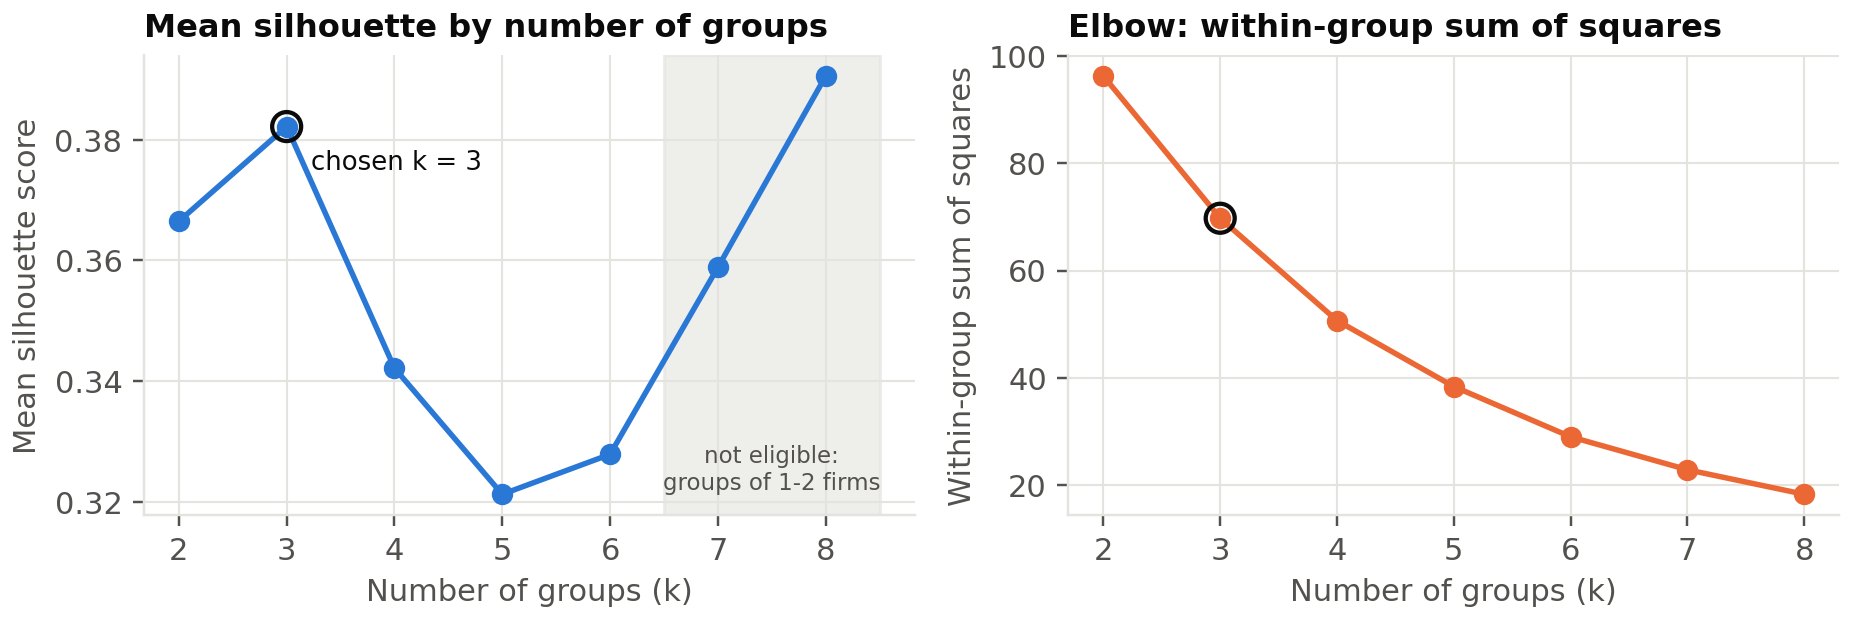

In [14]:
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#ffffff"
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8e5bd0", "#d43d6a", "#5a6b7a", "#7fae2a"]
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2})

fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.0), dpi=220)
ks = list(K_RANGE)
axes[0].plot(ks, [SIL[k] for k in ks], marker="o", color=PALETTE[0], linewidth=1.8)
axes[0].scatter([K], [SIL[K]], s=90, facecolor="none", edgecolor=INK, linewidth=1.4, zorder=3)
axes[0].annotate(f"chosen k = {K}", (K, SIL[K]), xytext=(8, -14), textcoords="offset points", fontsize=8.5, color=INK)
inel = [k for k in ks if k not in VALID]
if inel:
    axes[0].axvspan(min(inel) - 0.5, max(inel) + 0.5, color=GRID, alpha=0.6, zorder=0)
    axes[0].text((min(inel) + max(inel)) / 2, min(SIL.values()), "not eligible:\ngroups of 1-2 firms", ha="center", va="bottom", fontsize=7.5, color=INK2)
axes[0].set_title("Mean silhouette by number of groups", loc="left", fontsize=10.5, fontweight="bold", color=INK)
axes[0].set_xlabel("Number of groups (k)"); axes[0].set_ylabel("Mean silhouette score")
axes[1].plot(ks, [INERTIA[k] for k in ks], marker="o", color=PALETTE[1], linewidth=1.8)
axes[1].scatter([K], [INERTIA[K]], s=90, facecolor="none", edgecolor=INK, linewidth=1.4, zorder=3)
axes[1].set_title("Elbow: within-group sum of squares", loc="left", fontsize=10.5, fontweight="bold", color=INK)
axes[1].set_xlabel("Number of groups (k)"); axes[1].set_ylabel("Within-group sum of squares")
for ax in axes:
    ax.grid(color=GRID, linewidth=0.7); ax.set_xticks(ks)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
fig.tight_layout()
fig.savefig(HERE / "k_selection.png", facecolor=SURF, bbox_inches="tight", pad_inches=0.06)
plt.close(fig)
display(IPImage(str(HERE / "k_selection.png")))

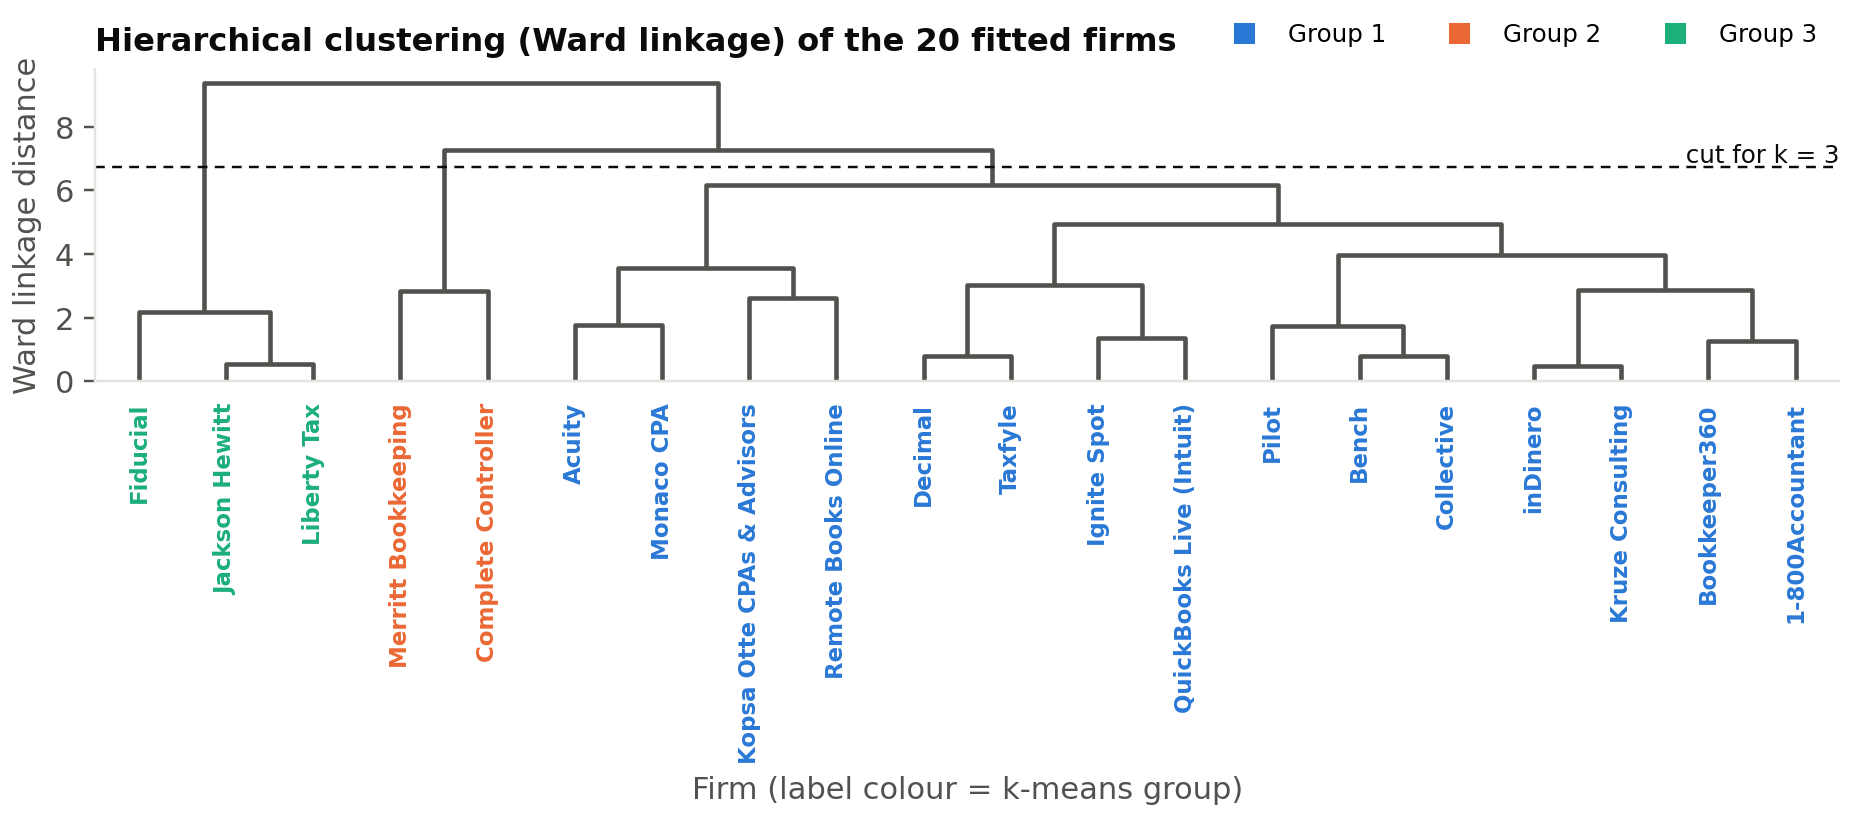

In [15]:
fig, ax = plt.subplots(figsize=(8.6, 3.9), dpi=220)
LINK = linkage(Z, method="ward")
dn = dendrogram(LINK, labels=[NAME[s] for s in F.index], leaf_rotation=90, leaf_font_size=7.5, ax=ax, color_threshold=0, above_threshold_color=INK2)
by_name = {NAME[s]: g for s, g in zip(F.index, LAB)}
for t in ax.get_xticklabels():
    t.set_color(PALETTE[by_name[t.get_text()]]); t.set_fontweight("bold")
cut = (LINK[-K, 2] + LINK[-K + 1, 2]) / 2          # height between the (K-1)th and Kth merge from the top gives K clusters
ax.axhline(cut, color=INK, linewidth=0.8, linestyle=(0, (4, 3)))
ax.text(ax.get_xlim()[1], cut, f" cut for k = {K}", va="bottom", ha="right", fontsize=8, color=INK)
ax.legend(handles=[Line2D([], [], marker="s", linestyle="", color=PALETTE[g], label=f"Group {g + 1}") for g in range(K)],
          loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=K, frameon=False, fontsize=8)   # above the plot area, clear of the tree
ax.set_title(f"Hierarchical clustering (Ward linkage) of the {len(F)} fitted firms", loc="left", fontsize=10.5, fontweight="bold", color=INK)
ax.set_xlabel("Firm (label colour = k-means group)"); ax.set_ylabel("Ward linkage distance")
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
fig.tight_layout()
fig.savefig(HERE / "dendrogram.png", facecolor=SURF, bbox_inches="tight", pad_inches=0.06)
plt.close(fig)
display(IPImage(str(HERE / "dendrogram.png")))

/var/folders/db/f5jfdp_d57x2bt3v4m8_lsgm0000gn/T/ipykernel_83166/1383244285.py:45: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  PROF["firms"] = F.groupby("group").apply(lambda d: ", ".join(NAME[s] for s in d.index))


,name,log_price,price_published,breadth,log_locations,channel,niche,files_tax,n,firms
group,,,,,,,,,,
0,online bookkeeping + tax filing,2.43,0.67,7.67,0.02,0.13,0.27,1.0,15,"Kopsa Otte CPAs & Advisors, Bench, Pilot, Bookkeeper360, 1-800Accountant, inDinero, Ig..."
1,bookkeeping only (no tax filing),2.16,1.00,4.50,0.00,0.00,0.00,0.0,2,"Merritt Bookkeeping, Complete Controller"
2,office-network tax preparers,2.36,0.00,4.67,2.83,2.00,0.00,1.0,3,"Jackson Hewitt, Liberty Tax, Fiducial"


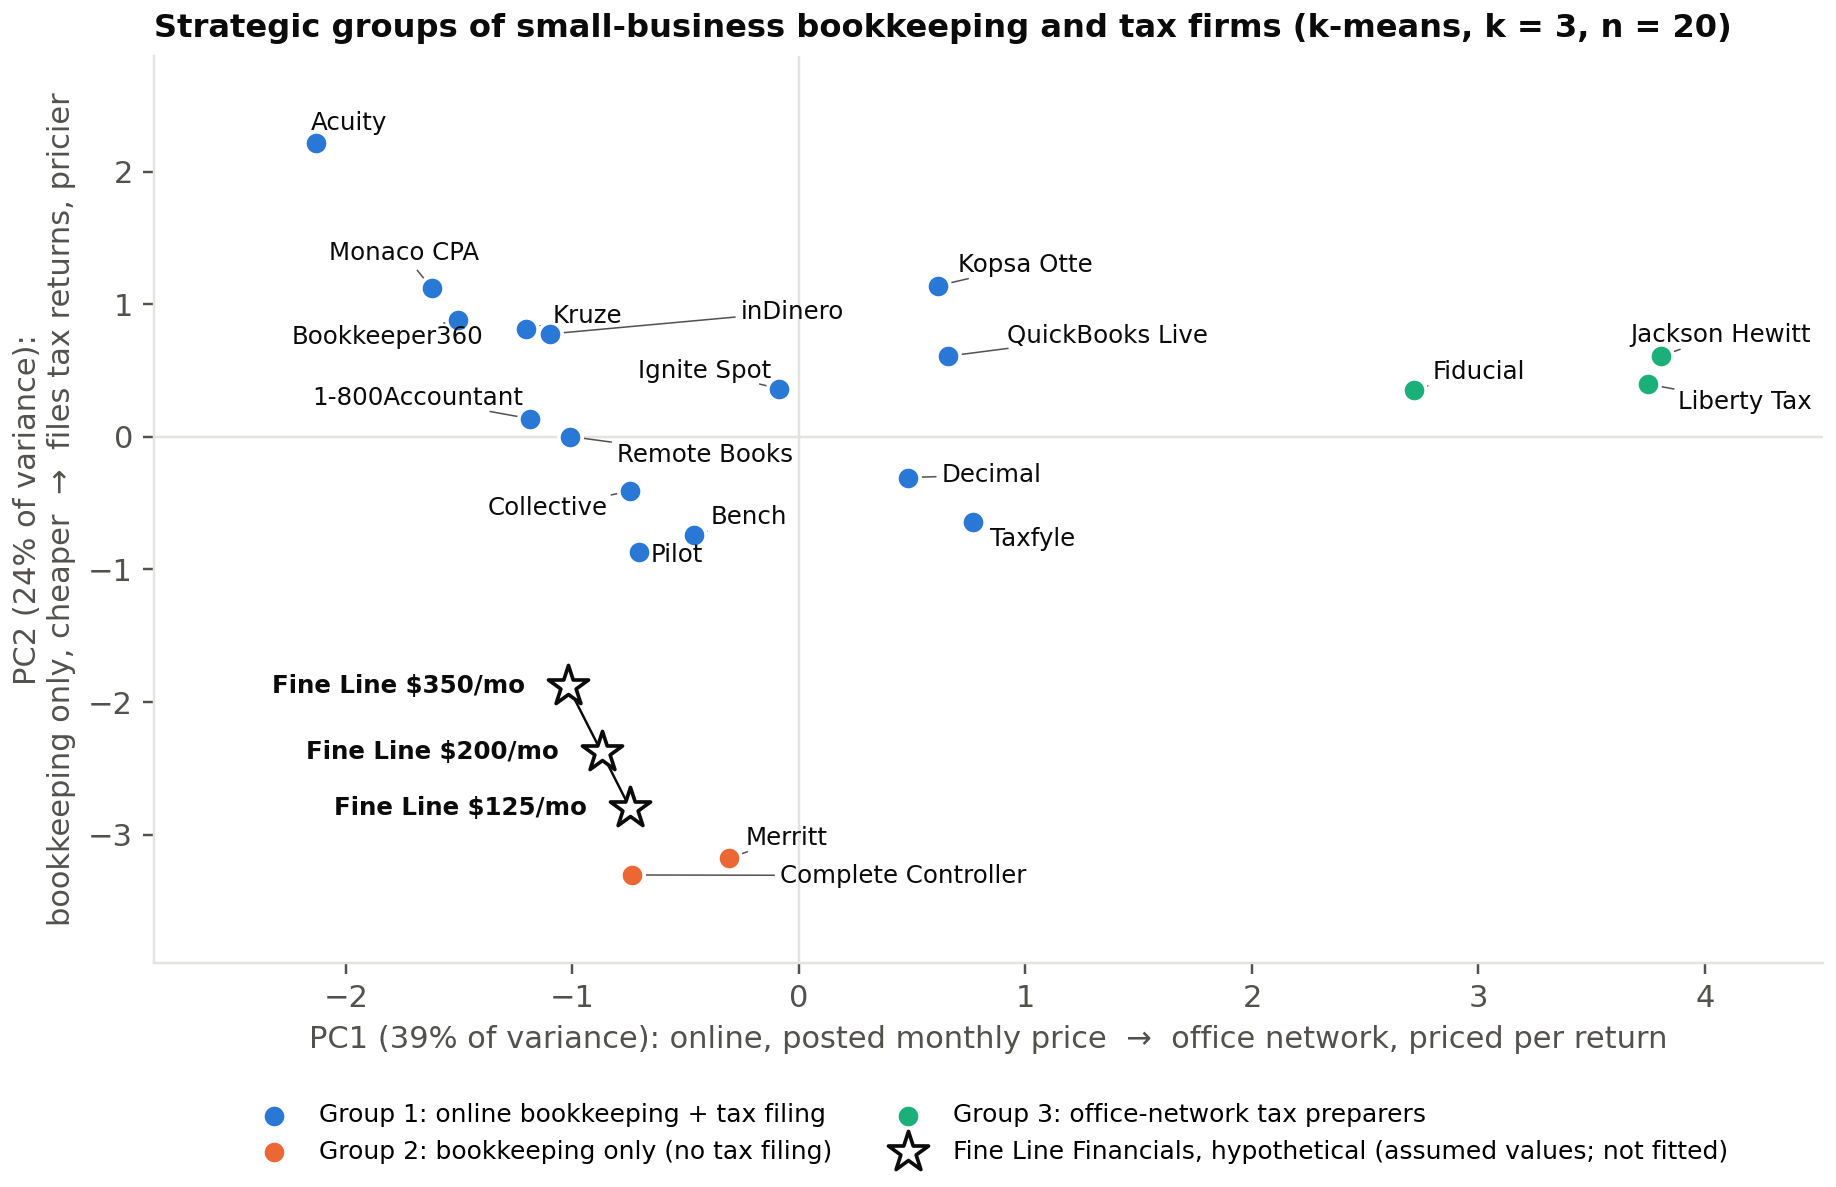

In [16]:
SHORT = {"Kopsa Otte CPAs & Advisors": "Kopsa Otte", "QuickBooks Live (Intuit)": "QuickBooks Live", "Remote Books Online": "Remote Books",
         "Merritt Bookkeeping": "Merritt", "Kruze Consulting": "Kruze", "Complete Controller": "Complete Controller"}
def map_chart(path, axis_names, group_names):
    fig, ax = plt.subplots(figsize=(8.6, 5.6), dpi=220)
    texts = []
    for g in range(K):
        sel = F[F.group == g]
        ax.scatter(sel.pc1, sel.pc2, s=58, color=PALETTE[g], edgecolor=SURF, linewidth=1.2, zorder=3, label=f"Group {g + 1}: {group_names[g]}")
        for s, r in sel.iterrows():
            texts.append(ax.text(r.pc1, r.pc2, SHORT.get(NAME[s], NAME[s]), fontsize=8, color=INK, zorder=4))
    mx, my = [m["pc1"] for m in MINE], [m["pc2"] for m in MINE]
    ax.plot(mx, my, color=INK, linewidth=0.8, zorder=2)
    ax.scatter(mx, my, marker="*", s=190, color=SURF, edgecolor=INK, linewidth=1.2, zorder=5,
               label="Fine Line Financials, hypothetical (assumed values; not fitted)")
    for m in MINE:
        ax.annotate(f"Fine Line ${m['price']}/mo", (m["pc1"], m["pc2"]), xytext=(-14, 0), textcoords="offset points",
                    ha="right", va="center", fontsize=8, color=INK, fontweight="bold", zorder=6)   # placed by hand in the empty space to the left
    xs = list(F.pc1) + mx; ys = list(F.pc2) + my
    padx, pady = 0.12 * (max(xs) - min(xs)), 0.12 * (max(ys) - min(ys))
    ax.set_xlim(min(xs) - padx, max(xs) + padx); ax.set_ylim(min(ys) - pady, max(ys) + pady)
    ax.axhline(0, color=GRID, linewidth=0.8, zorder=1); ax.axvline(0, color=GRID, linewidth=0.8, zorder=1)
    adjust_text(texts, x=xs, y=ys, ax=ax, expand=(1.25, 1.5), force_text=(0.4, 0.6), force_static=(0.3, 0.5),
                arrowprops=dict(arrowstyle="-", color=INK2, linewidth=0.5), ensure_inside_axes=True, max_move=None)
    ax.set_title(f"Strategic groups of small-business bookkeeping and tax firms (k-means, k = {K}, n = {len(F)})",
                 loc="left", fontsize=10.5, fontweight="bold", color=INK)
    ax.set_xlabel(f"PC1 ({EVR[0]:.0%} of variance): {axis_names[0]}")
    ax.set_ylabel(f"PC2 ({EVR[1]:.0%} of variance):\n{axis_names[1]}")
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, frameon=False, fontsize=8.2)   # below the plot area, clear of every point
    fig.tight_layout()
    fig.savefig(path, facecolor=SURF, bbox_inches="tight", pad_inches=0.06)
    plt.close(fig)

# group profiles; groups are named by a fixed rule from their own averages, not by hand
PROF = X.assign(group=F.group).groupby("group").mean()
def group_name(r):
    if r.files_tax < 0.5:
        return "bookkeeping only (no tax filing)"
    if r.channel >= 1.5:
        return "office-network tax preparers"
    return "online bookkeeping + tax filing"
GNAME = [group_name(PROF.loc[g]) for g in range(K)]
PROF.insert(0, "name", GNAME)
PROF["n"] = F.groupby("group").size()
PROF["firms"] = F.groupby("group").apply(lambda d: ", ".join(NAME[s] for s in d.index))
display(PROF.round(2))

# plain-English axis names, read from the loadings table in section 6 (the assert stops the run if the loadings no longer say this)
top = lambda pc, n=2: list(LOAD[pc].abs().sort_values(ascending=False).index[:n])
assert set(top("PC1")) == {LABEL["log_locations"], LABEL["channel"]} and LOAD.PC1[LABEL["price_published"]] < -0.3, "re-read PC1"
assert set(top("PC2")) == {LABEL["files_tax"], LABEL["log_price"]} or set(top("PC2")) == {LABEL["files_tax"], LABEL["breadth"]}, "re-read PC2"
AXIS = ["online, posted monthly price  →  office network, priced per return",
        "bookkeeping only, cheaper  →  files tax returns, pricier"]
map_chart(HERE / "competitor_map.png", AXIS, GNAME)
display(IPImage(str(HERE / "competitor_map.png")))

## 11. What the two axes represent (read from the loadings)

In [17]:
pc3 = pd.Series(pca.components_[2], index=[LABEL[c] for c in FEATS])
PC3_TOP = list(pc3.abs().sort_values(ascending=False).index[:2]); PC3_LOAD = [pc3[i] for i in PC3_TOP]
show(f"""**PC1 ({EVR[0]:.0%} of the variance): physical presence and how the firm prices.** It loads on walk-in locations ({LOAD.PC1[LABEL['log_locations']]:+.2f})
and channel ({LOAD.PC1[LABEL['channel']]:+.2f}) on one side, and on publishing a monthly price ({LOAD.PC1[LABEL['price_published']]:+.2f}) and service
breadth ({LOAD.PC1[LABEL['breadth']]:+.2f}) on the other. Right means a branch network that sells tax returns one at a time with no posted monthly
plan (Jackson Hewitt, Liberty Tax, Fiducial); left means an online firm with a posted subscription price and a longer service list. It is
the old storefront-versus-subscription split.

**PC2 ({EVR[1]:.0%} of the variance): how far the firm goes past the books.** It loads on filing tax returns ({LOAD.PC2[LABEL['files_tax']]:+.2f}),
starting price ({LOAD.PC2[LABEL['log_price']]:+.2f}), service breadth ({LOAD.PC2[LABEL['breadth']]:+.2f}) and, more weakly, beauty niche
({LOAD.PC2[LABEL['niche']]:+.2f}). The bottom is bookkeeping only at a low monthly price (Merritt, Complete Controller); the top is a firm that
also prepares returns, charges more and lists more services (Acuity, Kruze, Monaco CPA, Bookkeeper360).

Together they explain {EVR[:2].sum():.0%} of the variance. The remaining {1 - EVR[:2].sum():.0%} is not visible on the map but is used by k-means;
the next component, PC3 ({EVR[2]:.0%}), is mostly {PC3_TOP[0]} ({PC3_LOAD[0]:+.2f}) and {PC3_TOP[1]} ({PC3_LOAD[1]:+.2f}).""")

## 12. The groups, the surprise, and the comparison with groups drawn by hand

In [18]:
HAND = pd.crosstab(F.hand_group, F.group.map(lambda g: f"Group {g + 1}"))
BEAUTY = [s_ for s_ in F.index if F.loc[s_, "niche"] == 1]
# smallest number of Ward clusters at which the niche firms sit together with no other firm
BEAUTY_K = next((k for k in range(K, len(F)) if (lambda lab: len({lab[F.index.get_loc(s_)] for s_ in BEAUTY}) == 1 and
                 sum(lab == lab[F.index.get_loc(BEAUTY[0])]) == len(BEAUTY))(AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Z))), None)
print("Firms with a beauty page:", ", ".join(NAME[s_] for s_ in BEAUTY), f"| they form their own Ward cluster from k = {BEAUTY_K}")
ARI_HAND = adjusted_rand_score(F.hand_group, F.group)
display(HAND)
gid = lambda slug: int(F.loc[slug, "group"])
DROPS = DROP.set_index("attribute dropped")["ARI vs full fit"]
NN = np.sort(np.linalg.norm(Z[:, None] - Z[None], axis=2) + np.diag([np.inf] * len(Z)), axis=1)[:, 0]
# the sentences below describe this run's result; refuse to print them if the numbers no longer say so
assert K == 3 and gid("jackson_hewitt") == gid("liberty_tax") == gid("fiducial") and gid("merritt") == gid("complete_controller")
assert len({gid(s) for s in ("kopsa_otte", "remote_books", "acuity", "monaco_cpa", "bench", "pilot")}) == 1 and DROPS["niche"] > 0.999 and BEAUTY_K and BEAUTY_K > K
assert all(GNAME[m["group"]] == "bookkeeping only (no tax filing)" for m in MINE)
G_ONLINE, G_BOOKS, G_OFFICE = gid("bench"), gid("merritt"), gid("jackson_hewitt")
show(f"""**The groups (k = {K}, silhouette {SIL[K]:.2f}; Ward hierarchical clustering gives the identical partition, ARI {ARI_HC:.2f}).**

* **Group {G_ONLINE + 1}, {GNAME[G_ONLINE]} ({PROF.n[G_ONLINE]} firms):** {PROF.firms[G_ONLINE]}.
* **Group {G_BOOKS + 1}, {GNAME[G_BOOKS]} ({PROF.n[G_BOOKS]} firms):** {PROF.firms[G_BOOKS]}.
* **Group {G_OFFICE + 1}, {GNAME[G_OFFICE]} ({PROF.n[G_OFFICE]} firms):** {PROF.firms[G_OFFICE]}.

A silhouette of {SIL[K]:.2f} is weak-to-moderate structure: the two small groups are clearly apart, but the large online group is a loose
cloud rather than a tight cluster.

**The surprise: the beauty specialists do not form a group of their own at the k the data prefers.** Kopsa Otte (a salon-and-spa CPA firm for 40 years), Remote Books Online, Acuity
and Monaco CPA all have salon or spa pages, and I expected them to cluster together. Instead they sit inside the online group next to startup
specialists such as Pilot and Kruze. Dropping the niche feature entirely leaves every firm in the same group (ARI {DROPS['niche']:.2f}). With these
attributes, serving salons is a marketing page on top of an ordinary online bookkeeping-and-tax model, not a different business model. The
dendrogram does put the {len(BEAUTY)} beauty-page firms on one branch of their own, and that branch splits off as a separate cluster at k = {BEAUTY_K}.
But the silhouette falls when it does (from {SIL[K]:.2f} at k = {K} to {SIL[BEAUTY_K]:.2f}), so the beauty firms are a weaker sub-niche inside the
online group, not a separate strategic group. What
actually splits the industry is whether a firm files tax returns (dropping it: ARI {DROPS['files_tax']:.2f}) and whether it has a storefront
network (dropping footprint: ARI {DROPS['footprint']:.2f}).

**Against the groups I drew by hand** (national online bookkeeping, advisory/CFO, tax-prep chains, beauty-niche specialists; written in
`competitors.json` before the fit) the agreement is low (ARI {ARI_HAND:.2f}). The data keeps one of my lines, the tax-prep chains, and adds one
I did not draw, bookkeeping-only. It merges three of my four categories into a single online group. My hand groups sorted firms by **who they
sell to** (startups, salons, everyone); the data sorts them by **what they sell and how they deliver it** (tax filing or not, storefront or not).
So either the public attributes cannot see customer focus beyond a yes/no niche flag, or, more likely, the online segment really is one crowded
strategic group whose members differ mainly in marketing.""")

Firms with a beauty page: Kopsa Otte CPAs & Advisors, Remote Books Online, Acuity, Monaco CPA | they form their own Ward cluster from k = 4


group,Group 1,Group 2,Group 3
hand_group,,,
Advisory / CFO firms,4,0,0
Beauty-niche specialists,3,0,0
National online bookkeeping,7,2,0
Tax-prep chains,1,0,3


## 13. What the hypothetical point shows (assumptions, not data)

In [19]:
DC = [np.linalg.norm(CENTERS - scaler.transform(my_row(m["price"])), axis=1) for m in MINE]
show(f"""At all three prices Fine Line Financials lands nearest the **{GNAME[MINE[0]['group']]}** group, because it does not file tax returns. Its nearest
competitor in every scenario is {MINE[0]['neighbours'][0]}, at a distance of {min(m['nn_dist'][0] for m in MINE):.1f}-{max(m['nn_dist'][0] for m in MINE):.1f}
in standardized units. For comparison, the typical competitor's nearest neighbour is {np.median(NN):.1f} away. So the point sits in **open space**: no
competitor combines a beauty niche, no tax filing and a posted price.

Raising the price from $125 to $350 moves the point up PC2 by {MINE[-1]['pc2'] - MINE[0]['pc2']:.1f} units, toward the full-service online firms.
Its distance to the online group's centre shrinks from {DC[0][G_ONLINE]:.2f} to {DC[-1][G_ONLINE]:.2f}, and its distance to the bookkeeping-only centre grows from
{DC[0][G_BOOKS]:.2f} to {DC[-1][G_BOOKS]:.2f}, but the nearest group does not change. On these attributes, the
**decision not to file tax returns places the firm more than its price does**. At $350 it is priced like the full-service firms while offering what
the bookkeeping-only firms offer.""")

## 14. Limits

In [20]:
assert SEED_SAME < 0.5 and HOLD < 1
LIMITS = [
    f"**Small n.** {len(F)} fitted firms. Silhouette scores are noisy at this size, and one firm can move a group boundary: single-start k-means "
    f"matched the final groups in only {SEED_SAME:.0%} of 100 seeds, so 50 starts per fit were needed for a stable answer.",
    "**The attributes were chosen by me.** A different checklist, or weights on its items, would change the breadth counts. There are only seven "
    "features, and two of them (files tax returns, walk-in footprint) carry the grouping.",
    f"**Sources are dated and public only.** Every value was read on its retrieval date ({', '.join(sorted(set(PAGE_TABLE.retrieved)))}; NPS reviews "
    "2026-10-08) from the firm's own public pages. Prices change, and these pages are marketing; review figures shown on a firm's own site are self-selected. "
    "Pages that refused a plain request (Xendoo, Block Advisors, Padgett, Straight Talk CPAs and some subpages) are recorded as missing, not estimated.",
    f"**Missing values.** The quality signal (reviews) was missing for {ATTR_SHARE['reviews']:.0%} of operating firms and is left out of the fit. "
    f"{int((IMP.feature == LABEL['log_price']).sum())} firms with no posted monthly price were given the median price plus a flag, and "
    f"{len(IMP) - int((IMP.feature == LABEL['log_price']).sum())} other cells were imputed. Each one is listed in the notebook's imputation table and starred in the attribute table.",
    f"**Clustering is sensitive to scaling and encoding.** Standardizing gives every feature, including each yes/no flag, equal say; the log "
    f"transforms and the 0/1/2 channel scale are choices. Dropping a single feature changed the groups in {1 - HOLD:.0%} of the drop-one runs (the stability table).",
    "**Fine Line Financials' points are hypothetical.** They are assumed values, projected after fitting; they are not data and did not affect the groups.",
]
show("\n".join(f"* {l}" for l in LIMITS))

## 15. Save results for the PDF, and keep only the lines the analysis uses

`cache/full/` (whole page text) is git-ignored. `cache/pages/*.json` keeps, for each page, the lines that hold a checked quote, a checklist
or beauty-term match, or a 2025/2026 date (about pages: only quote and date lines, so staff bios are not republished). That is enough for a fresh clone to re-run every check and get the same result.

In [21]:
QUOTES = {}
for s_, f in ATTR.items():
    for a, v in f.items():
        if isinstance(v, dict) and v.get("quote") and v.get("url", "").startswith("http"):
            QUOTES.setdefault(v["url"], []).append(v["quote"])
PATTERNS = list(CHECKLIST.values()) + [BEAUTY_RX.pattern, r"20(25|26)"]
kept = {u: fetch.keep_lines(u, PATTERNS if "about" not in u.lower() else [r"20(25|26)"], QUOTES.get(u, [])) for u in PAGES}
print(f"kept {sum(kept.values())} lines across {sum(1 for v in kept.values() if v)} pages "
      f"({'from full text' if any(PAGES[u]['from'] == 'full text' for u in PAGES) else 'already reduced: fresh-clone run'})")

def src_list(slug):
    return [{"url": u, "retrieved": retrieved(u)} for u in T.loc[slug, "sources"]]
RESULTS = {
    "generated": dt.date.today().isoformat(),
    "retrieved": sorted(set(PAGE_TABLE.retrieved)),
    "n_input": len(COMP), "n_fit": len(F), "k": K, "silhouette": {str(k): round(float(v), 3) for k, v in SIL.items()},
    "eligible_k": VALID, "k_best_any": K_BEST_ANY, "evr": [round(float(v), 4) for v in EVR], "features": [LABEL[c] for c in FEATS],
    "loadings": {i: {"PC1": round(float(r.PC1), 3), "PC2": round(float(r.PC2), 3)} for i, r in LOAD.iterrows()},
    "axis": AXIS, "ari_hc": round(float(ARI_HC), 3), "hc_diff": HC_DIFF, "ari_hand": round(float(ARI_HAND), 3),
    "seed_same_1start": SEED_SAME, "seed_same_50": float(np.mean(np.array(seed_ari50) > 0.999)), "seed_median_ari": float(np.median(seed_ari)),
    "drop": DROP.to_dict("records"), "hold": HOLD,
    "switch": {NAME[s_]: int(n) for s_, n in switch_count.items() if n > 0},
    "groups": [{"id": g + 1, "name": GNAME[g], "firms": [NAME[s_] for s_ in F.index[F.group == g]],
                "profile": {c: round(float(PROF.loc[g, c]), 2) for c in FEATS}} for g in range(K)],
    "hand": {"rows": HAND.index.tolist(), "cols": HAND.columns.tolist(), "values": HAND.values.tolist()},
    "mine": [{**{k_: (float(v) if isinstance(v, (np.floating, float)) else v) for k_, v in m.items()},
              "group_name": GNAME[m["group"]], "d_centres": [round(float(x), 2) for x in d]} for m, d in zip(MINE, DC)],
    "my_breadth": MY_BREADTH, "nn_median": round(float(np.median(NN)), 2),
    "imputed": IMP.to_dict("records"), "attr_share": ATTR_SHARE, "dropped_attr": DROPPED_ATTR, "limits": LIMITS,
    "status": {NAME[s_]: {"status": v[0], "basis": v[1]} for s_, v in STATUS.items()},
    "checklist": list(CHECKLIST), "pages_total": len(PAGE_TABLE), "pages_read": int((PAGE_TABLE.status == 200).sum()),
    "quotes_checked": n_q,
    "table": [{"slug": s_, "firm": r.firm, "status": r.status, "fitted": bool(r.fitted), "group": (int(F.loc[s_, "group"]) + 1 if s_ in F.index else None),
               "price_status": r.price_status, "price": r.price, "breadth": None if pd.isna(r.breadth) else int(r.breadth),
               "locations": None if pd.isna(r.locations) else int(r.locations), "channel": r.channel, "channel_basis": r.channel_basis,
               "niche": None if pd.isna(r.niche) else int(r.niche), "files_tax": None if pd.isna(r.files_tax) else int(r.files_tax),
               "review_score": None if pd.isna(r.review_score) else float(r.review_score),
               "review_count": None if pd.isna(r.review_count) else int(r.review_count), "review_source": r.review_source,
               "missing": r.missing, "imputed": sorted(i["feature"] for i in IMPUTED if i["firm"] == r.firm),
               "sources": src_list(s_)} for s_, r in T.iterrows()],
}
(HERE / "results.json").write_text(json.dumps(RESULTS, indent=1, default=str))
print("wrote results.json")

kept 2577 lines across 81 pages (from full text)
wrote results.json
